# Multi Layer Perceptron (MLP) implementado do zero × Scikit-Learn

Neste notebook eu implemento uma rede neural **Multi Layer Perceptron** usando apenas **NumPy** e comparo seu desempenho com as implementações do Scikit-Learn (`MLPClassifier` e `MLPRegressor`).

A MLP implementada é configurável em:

- **quantidade de camadas ocultas** e **quantidade de neurônios em cada camada** — parâmetro `camadas_ocultas`, ex.: `(64, 32)`;
- **função de ativação de cada camada** — parâmetro `ativacoes`, que aceita uma única função para todas as camadas (`'relu'`) ou uma lista com uma função por camada (`['relu', 'tanh']`). Isso é algo que o Scikit-Learn **não** permite: lá todas as camadas ocultas usam a mesma ativação;
- otimizador (`'sgd'` com momento ou `'adam'`), taxa de aprendizado, regularização L2, tamanho do lote, critério de parada etc.

**Roteiro**

1. Funções de ativação
2. Implementação da MLP
3. Testes de corretude da implementação
4. Classificação 2D (`make_moons`) — fronteira de decisão
5. Classificação de dígitos manuscritos (`load_digits`)
6. Comparação de arquiteturas e funções de ativação
7. Regressão
8. Conclusões

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, load_diabetes, make_moons
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier as SkMLPClassifier
from sklearn.neural_network import MLPRegressor as SkMLPRegressor
from sklearn.preprocessing import StandardScaler

# O sklearn avisa quando atinge max_iter sem convergir; nos experimentos isso é esperado.
warnings.filterwarnings('ignore', category=ConvergenceWarning)
plt.rcParams['figure.dpi'] = 100

## 1. Funções de ativação

Cada função de ativação é guardada junto com sua derivada. A derivada recebe tanto a pré-ativação $Z$ quanto a saída $A = f(Z)$, pois para algumas funções é mais barato calcular a derivada a partir da saída (ex.: $\sigma'(z) = \sigma(z)(1-\sigma(z))$ e $\tanh'(z) = 1 - \tanh^2(z)$).

| Nome | $f(z)$ | $f'(z)$ |
|---|---|---|
| `identidade` | $z$ | $1$ |
| `sigmoide` | $1/(1+e^{-z})$ | $f(z)(1-f(z))$ |
| `tanh` | $\tanh(z)$ | $1-f(z)^2$ |
| `relu` | $\max(0, z)$ | $1$ se $z>0$, senão $0$ |
| `leaky_relu` | $z$ se $z>0$, senão $0{,}01z$ | $1$ se $z>0$, senão $0{,}01$ |
| `softmax` | $e^{z_k}/\sum_j e^{z_j}$ | (usada só na saída, junto com a entropia cruzada) |

Os nomes usados pelo Scikit-Learn (`identity`, `logistic`) também são aceitos como sinônimos.

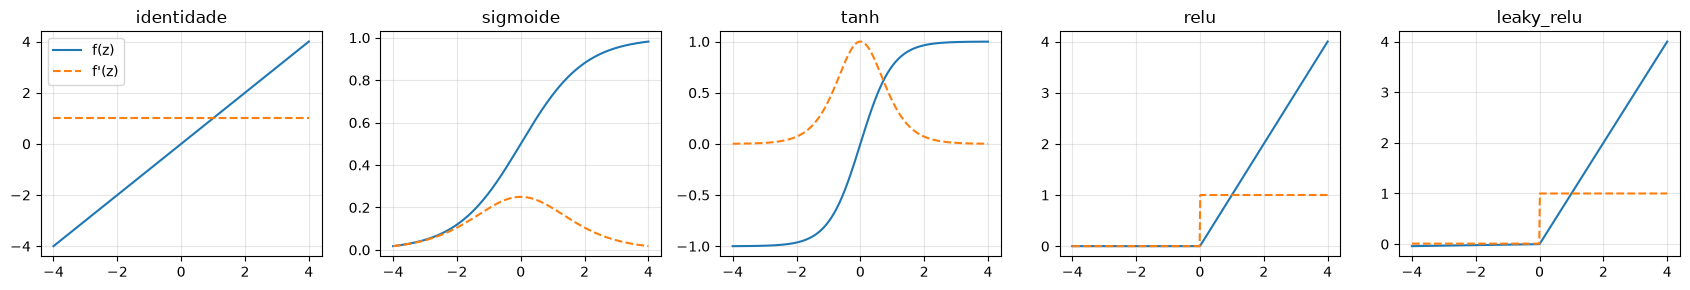

In [2]:
def _sigmoide(z):
    # Forma equivalente a 1/(1+e^-z) que não estoura para |z| grande
    return 0.5 * (1.0 + np.tanh(0.5 * z))


def _softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


# nome -> (função, derivada(z, a))
ATIVACOES = {
    'identidade': (lambda z: z,                              lambda z, a: np.ones_like(z)),
    'sigmoide':   (_sigmoide,                                lambda z, a: a * (1 - a)),
    'tanh':       (np.tanh,                                  lambda z, a: 1 - a ** 2),
    'relu':       (lambda z: np.maximum(z, 0),               lambda z, a: (z > 0).astype(z.dtype)),
    'leaky_relu': (lambda z: np.where(z > 0, z, 0.01 * z),   lambda z, a: np.where(z > 0, 1.0, 0.01)),
    'softmax':    (_softmax,                                 None),
}
SINONIMOS = {'identity': 'identidade', 'linear': 'identidade', 'logistic': 'sigmoide', 'sigmoid': 'sigmoide'}

z = np.linspace(-4, 4, 400)
fig, eixos = plt.subplots(1, 5, figsize=(17, 3), sharex=True)
for ax, nome in zip(eixos, ['identidade', 'sigmoide', 'tanh', 'relu', 'leaky_relu']):
    f, df = ATIVACOES[nome]
    a = f(z)
    ax.plot(z, a, label='f(z)')
    ax.plot(z, df(z, a), '--', label="f'(z)")
    ax.set_title(nome)
    ax.grid(alpha=0.3)
eixos[0].legend()
plt.tight_layout()
plt.show()

## 2. Implementação da MLP

Notação: a rede tem $L$ camadas com pesos; $A^{(0)} = X$ é a entrada e $A^{(L)}$ é a saída.

**Propagação direta**

$$Z^{(l)} = A^{(l-1)} W^{(l)} + b^{(l)}, \qquad A^{(l)} = f_l\big(Z^{(l)}\big)$$

onde $f_l$ é a ativação escolhida para a camada $l$. A ativação da camada de saída é definida pelo problema, como no Scikit-Learn:
softmax (multiclasse), sigmoide (binário) ou identidade (regressão).

**Função de perda** (lote com $n$ amostras e regularização L2 com coeficiente $\alpha$)

- Classificação: entropia cruzada $\; \mathcal{L} = -\frac{1}{n}\sum_i \sum_k y_{ik}\log \hat y_{ik} + \frac{\alpha}{2n}\sum_l \lVert W^{(l)} \rVert^2$
- Regressão: erro quadrático $\; \mathcal{L} = \frac{1}{2n}\sum_i \lVert y_i - \hat y_i \rVert^2 + \frac{\alpha}{2n}\sum_l \lVert W^{(l)} \rVert^2$

**Retropropagação**

Para softmax/sigmoide + entropia cruzada e identidade + erro quadrático, o gradiente na saída simplifica para $\delta^{(L)} = \frac{1}{n}(A^{(L)} - Y)$
(no caso geral de regressão multiplica-se ainda por $f_L'(Z^{(L)})$). Em seguida, camada a camada, de trás para frente:

$$\frac{\partial \mathcal{L}}{\partial W^{(l)}} = A^{(l-1)\top}\delta^{(l)} + \frac{\alpha}{n}W^{(l)}, \qquad
\frac{\partial \mathcal{L}}{\partial b^{(l)}} = \sum_i \delta^{(l)}_i, \qquad
\delta^{(l-1)} = \big(\delta^{(l)} W^{(l)\top}\big) \odot f'_{l-1}\big(Z^{(l-1)}\big)$$

**Otimizadores**

- `sgd`: gradiente descendente estocástico com momento: $v \leftarrow \mu v - \eta \nabla$, $\;\theta \leftarrow \theta + v$
- `adam`: Adam (Kingma & Ba, 2014) com correção de viés.

**Inicialização e parada** — seguem as mesmas escolhas do Scikit-Learn para que a comparação seja justa: pesos e vieses uniformes em $\pm\sqrt{6/(n_{in}+n_{out})}$ (Glorot; fator 2 no lugar de 6 para a sigmoide), mini-lotes de `min(200, n)` amostras embaralhados a cada época, e parada quando a perda de treino não melhora pelo menos `tol` durante `n_epocas_sem_melhora` épocas consecutivas.

Os valores padrão dos hiperparâmetros também são os mesmos do Scikit-Learn:

| Nossa MLP | Scikit-Learn | Padrão |
|---|---|---|
| `camadas_ocultas` | `hidden_layer_sizes` | `(100,)` |
| `ativacoes` | `activation` | `'relu'` |
| `solver` | `solver` | `'adam'` |
| `taxa_aprendizado` | `learning_rate_init` | `0.001` |
| `momento` | `momentum` | `0.9` |
| `alpha` | `alpha` | `0.0001` |
| `tamanho_lote` | `batch_size` | `200` |
| `max_epocas` | `max_iter` | `200` |
| `tol` | `tol` | `0.0001` |
| `n_epocas_sem_melhora` | `n_iter_no_change` | `10` |
| `semente` | `random_state` | `None` |

In [3]:
class _MLPBase:
    """Base comum da MLP para classificação e regressão.

    Parâmetros
    ----------
    camadas_ocultas : sequência de int
        Número de neurônios de cada camada oculta. O tamanho da sequência define
        a quantidade de camadas ocultas. Ex.: (64, 32) -> duas camadas ocultas.
    ativacoes : str ou sequência de str
        Função de ativação de cada camada oculta. Uma string aplica a mesma
        função a todas as camadas; uma lista deve ter uma função por camada.
        Opções: 'identidade', 'sigmoide', 'tanh', 'relu', 'leaky_relu'.
    solver : {'adam', 'sgd'}
    taxa_aprendizado, momento, alpha, tamanho_lote, max_epocas, tol,
    n_epocas_sem_melhora, beta1, beta2, epsilon, embaralhar, semente, verbose
        Hiperparâmetros do treinamento (ver tabela acima).
    """

    def __init__(self, camadas_ocultas=(100,), ativacoes='relu', solver='adam',
                 taxa_aprendizado=1e-3, momento=0.9, alpha=1e-4, tamanho_lote=200,
                 max_epocas=200, tol=1e-4, n_epocas_sem_melhora=10,
                 beta1=0.9, beta2=0.999, epsilon=1e-8, embaralhar=True,
                 semente=None, verbose=False):
        self.camadas_ocultas = tuple(int(n) for n in camadas_ocultas)
        if any(n < 1 for n in self.camadas_ocultas):
            raise ValueError('Cada camada oculta precisa ter pelo menos 1 neurônio.')
        if isinstance(ativacoes, str):
            ativacoes = [ativacoes] * len(self.camadas_ocultas)
        if len(ativacoes) != len(self.camadas_ocultas):
            raise ValueError(f'Foram informadas {len(ativacoes)} ativações para '
                             f'{len(self.camadas_ocultas)} camadas ocultas.')
        self.ativacoes = [self._normalizar_ativacao(a) for a in ativacoes]
        if solver not in ('adam', 'sgd'):
            raise ValueError("solver deve ser 'adam' ou 'sgd'.")
        self.solver = solver
        self.taxa_aprendizado = taxa_aprendizado
        self.momento = momento
        self.alpha = alpha
        self.tamanho_lote = tamanho_lote
        self.max_epocas = max_epocas
        self.tol = tol
        self.n_epocas_sem_melhora = n_epocas_sem_melhora
        self.beta1, self.beta2, self.epsilon = beta1, beta2, epsilon
        self.embaralhar = embaralhar
        self.semente = semente
        self.verbose = verbose

    @staticmethod
    def _normalizar_ativacao(nome):
        nome = SINONIMOS.get(nome, nome)
        if nome not in ATIVACOES or nome == 'softmax':
            opcoes = [a for a in ATIVACOES if a != 'softmax']
            raise ValueError(f'Ativação desconhecida: {nome!r}. Opções: {opcoes}')
        return nome

    # ---------- métodos definidos pelas subclasses ----------
    def _preparar_alvos(self, y):
        """Define self.ativacao_saida_ e devolve os alvos como matriz (n, n_saidas)."""
        raise NotImplementedError

    def _perda(self, Y, P):
        raise NotImplementedError

    def _delta_saida(self, Z, A, Y):
        """Gradiente da perda em relação à pré-ativação da camada de saída."""
        raise NotImplementedError

    # ---------- inicialização ----------
    def _inicializar(self, X, y):
        X = np.asarray(X, dtype=float)
        Y = self._preparar_alvos(y)
        self._rng = np.random.default_rng(self.semente)
        tamanhos = [X.shape[1], *self.camadas_ocultas, Y.shape[1]]
        self.pesos_, self.vieses_ = [], []
        for n_in, n_out, ativ in zip(tamanhos[:-1], tamanhos[1:], self._todas_ativacoes()):
            fator = 2.0 if ativ == 'sigmoide' else 6.0
            limite = np.sqrt(fator / (n_in + n_out))
            self.pesos_.append(self._rng.uniform(-limite, limite, (n_in, n_out)))
            self.vieses_.append(self._rng.uniform(-limite, limite, n_out))
        return X, Y

    def _todas_ativacoes(self):
        return self.ativacoes + [self.ativacao_saida_]

    # ---------- propagação direta e retropropagação ----------
    def _propagar(self, X):
        """Retorna as pré-ativações Z e as ativações A de cada camada (A[0] = X)."""
        Z, A = [], [X]
        for W, b, nome in zip(self.pesos_, self.vieses_, self._todas_ativacoes()):
            Z.append(A[-1] @ W + b)
            A.append(ATIVACOES[nome][0](Z[-1]))
        return Z, A

    def _perda_e_gradientes(self, X, Y):
        n = len(X)
        Z, A = self._propagar(X)
        perda = self._perda(Y, A[-1])
        perda += 0.5 * self.alpha * sum(np.sum(W ** 2) for W in self.pesos_) / n

        L = len(self.pesos_)
        grad_W, grad_b = [None] * L, [None] * L
        delta = self._delta_saida(Z[-1], A[-1], Y)
        for l in range(L - 1, -1, -1):
            grad_W[l] = A[l].T @ delta + self.alpha * self.pesos_[l] / n
            grad_b[l] = delta.sum(axis=0)
            if l > 0:
                derivada = ATIVACOES[self.ativacoes[l - 1]][1]
                delta = (delta @ self.pesos_[l].T) * derivada(Z[l - 1], A[l])
        return perda, grad_W, grad_b

    # ---------- otimizadores ----------
    def _iniciar_otimizador(self):
        params = self.pesos_ + self.vieses_
        if self.solver == 'sgd':
            self._velocidade = [np.zeros_like(p) for p in params]
        else:
            self._m = [np.zeros_like(p) for p in params]
            self._v = [np.zeros_like(p) for p in params]
            self._t = 0

    def _atualizar_parametros(self, grads):
        params = self.pesos_ + self.vieses_  # atualizados in-place
        if self.solver == 'sgd':
            for p, g, v in zip(params, grads, self._velocidade):
                v *= self.momento
                v -= self.taxa_aprendizado * g
                p += v
        else:
            self._t += 1
            lr = (self.taxa_aprendizado * np.sqrt(1 - self.beta2 ** self._t)
                  / (1 - self.beta1 ** self._t))
            for p, g, m, v in zip(params, grads, self._m, self._v):
                m *= self.beta1
                m += (1 - self.beta1) * g
                v *= self.beta2
                v += (1 - self.beta2) * g ** 2
                p -= lr * m / (np.sqrt(v) + self.epsilon)

    # ---------- treinamento ----------
    def fit(self, X, y):
        X, Y = self._inicializar(X, y)
        self._iniciar_otimizador()
        n = len(X)
        lote = min(self.tamanho_lote, n)
        self.curva_perda_ = []
        melhor_perda, epocas_sem_melhora = np.inf, 0

        for epoca in range(1, self.max_epocas + 1):
            indices = self._rng.permutation(n) if self.embaralhar else np.arange(n)
            perda_acumulada = 0.0
            for inicio in range(0, n, lote):
                idx = indices[inicio:inicio + lote]
                perda, grad_W, grad_b = self._perda_e_gradientes(X[idx], Y[idx])
                self._atualizar_parametros(grad_W + grad_b)
                perda_acumulada += perda * len(idx)
            perda_epoca = perda_acumulada / n
            self.curva_perda_.append(perda_epoca)
            if self.verbose:
                print(f'Época {epoca}: perda = {perda_epoca:.6f}')

            # Critério de parada (mesmo do sklearn): perda não melhora 'tol' por várias épocas
            epocas_sem_melhora = epocas_sem_melhora + 1 if perda_epoca > melhor_perda - self.tol else 0
            melhor_perda = min(melhor_perda, perda_epoca)
            if epocas_sem_melhora > self.n_epocas_sem_melhora:
                break

        self.n_epocas_ = epoca
        return self

    def _saida(self, X):
        return self._propagar(np.asarray(X, dtype=float))[1][-1]

    def resumo(self):
        """Mostra a arquitetura da rede treinada."""
        print(f"{'Camada':<14}{'Neurônios':>10}   {'Ativação':<12}{'Parâmetros':>11}")
        print('-' * 50)
        print(f"{'entrada':<14}{self.pesos_[0].shape[0]:>10}")
        total = 0
        for i, (W, b, ativ) in enumerate(zip(self.pesos_, self.vieses_, self._todas_ativacoes())):
            nome = 'saída' if i == len(self.pesos_) - 1 else f'oculta {i + 1}'
            n_params = W.size + b.size
            total += n_params
            print(f'{nome:<14}{W.shape[1]:>10}   {ativ:<12}{n_params:>11}')
        print('-' * 50)
        print(f"{'Total de parâmetros treináveis:':<39}{total:>11}")


class MLPClassificador(_MLPBase):
    """MLP para classificação. Saída sigmoide (2 classes) ou softmax (3+ classes),
    treinada com entropia cruzada."""

    def _preparar_alvos(self, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        if len(self.classes_) < 2:
            raise ValueError('São necessárias pelo menos 2 classes.')
        if len(self.classes_) == 2:
            self.ativacao_saida_ = 'sigmoide'
            return (y == self.classes_[1]).astype(float).reshape(-1, 1)
        self.ativacao_saida_ = 'softmax'
        return (y[:, None] == self.classes_[None, :]).astype(float)  # one-hot

    def _perda(self, Y, P):
        P = np.clip(P, 1e-15, 1 - 1e-15)
        if self.ativacao_saida_ == 'softmax':
            return -np.sum(Y * np.log(P)) / len(Y)
        return -np.sum(Y * np.log(P) + (1 - Y) * np.log(1 - P)) / len(Y)

    def _delta_saida(self, Z, A, Y):
        return (A - Y) / len(Y)

    def predict_proba(self, X):
        P = self._saida(X)
        return np.hstack([1 - P, P]) if self.ativacao_saida_ == 'sigmoide' else P

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

    def score(self, X, y):
        return accuracy_score(y, self.predict(X))


class MLPRegressor(_MLPBase):
    """MLP para regressão, treinada com erro quadrático. A ativação da camada de
    saída é 'identidade' por padrão, mas pode ser trocada em `ativacao_saida`."""

    def __init__(self, *args, ativacao_saida='identidade', **kwargs):
        super().__init__(*args, **kwargs)
        self.ativacao_saida = self._normalizar_ativacao(ativacao_saida)

    def _preparar_alvos(self, y):
        y = np.asarray(y, dtype=float)
        self._saida_1d = y.ndim == 1
        self.ativacao_saida_ = self.ativacao_saida
        return y.reshape(len(y), -1)

    def _perda(self, Y, P):
        return 0.5 * np.sum((Y - P) ** 2) / len(Y)

    def _delta_saida(self, Z, A, Y):
        return (A - Y) / len(Y) * ATIVACOES[self.ativacao_saida_][1](Z, A)

    def predict(self, X):
        P = self._saida(X)
        return P.ravel() if self._saida_1d else P

    def score(self, X, y):
        return r2_score(y, self.predict(X))

Exemplo de uso — a quantidade de camadas, de neurônios e a ativação de cada camada são definidas na criação do modelo:

In [4]:
X_exemplo, y_exemplo = load_digits(return_X_y=True)

modelo = MLPClassificador(
    camadas_ocultas=(128, 64, 32),               # 3 camadas ocultas com 128, 64 e 32 neurônios
    ativacoes=['relu', 'tanh', 'leaky_relu'],    # uma ativação diferente em cada camada
    max_epocas=5,
    semente=0,
).fit(X_exemplo / 16, y_exemplo)

modelo.resumo()

Camada         Neurônios   Ativação     Parâmetros
--------------------------------------------------
entrada               64
oculta 1             128   relu               8320
oculta 2              64   tanh               8256
oculta 3              32   leaky_relu         2080
saída                 10   softmax             330
--------------------------------------------------
Total de parâmetros treináveis:              18986


Para comparar com o Scikit-Learn com os mesmos hiperparâmetros, uso uma função que traduz os parâmetros da nossa MLP para os nomes equivalentes do `MLPClassifier`/`MLPRegressor`. Como o Scikit-Learn não aceita ativações diferentes por camada, a função devolve `None` nesses casos. Também desligo o momento de Nesterov do `sgd` do sklearn, porque a nossa implementação usa o momento clássico.

In [5]:
PT_PARA_SK = {'identidade': 'identity', 'sigmoide': 'logistic', 'tanh': 'tanh', 'relu': 'relu'}
NOMES_SK = {
    'camadas_ocultas': 'hidden_layer_sizes', 'solver': 'solver',
    'taxa_aprendizado': 'learning_rate_init', 'momento': 'momentum', 'alpha': 'alpha',
    'tamanho_lote': 'batch_size', 'max_epocas': 'max_iter', 'tol': 'tol',
    'n_epocas_sem_melhora': 'n_iter_no_change', 'semente': 'random_state',
}


def modelo_sklearn(classe_sk, ativacoes='relu', **params):
    """Cria o modelo do scikit-learn equivalente aos parâmetros da nossa MLP."""
    if not isinstance(ativacoes, str):
        if len(set(ativacoes)) > 1:
            return None  # sklearn usa a mesma ativação em todas as camadas ocultas
        ativacoes = ativacoes[0]
    ativacao_sk = PT_PARA_SK.get(_MLPBase._normalizar_ativacao(ativacoes))
    if ativacao_sk is None:
        return None
    kwargs = {NOMES_SK[k]: v for k, v in params.items()}
    return classe_sk(activation=ativacao_sk, nesterovs_momentum=False, **kwargs)


def treinar(modelo, X, y):
    """Treina o modelo e devolve o tempo gasto em segundos."""
    inicio = time.perf_counter()
    modelo.fit(X, y)
    return time.perf_counter() - inicio

## 3. Testes de corretude

### 3.1 Verificação numérica do gradiente

A parte mais delicada de uma MLP é a retropropagação. Para testá-la, comparo o gradiente analítico com o gradiente numérico obtido por diferenças finitas centradas:

$$\frac{\partial \mathcal{L}}{\partial \theta} \approx \frac{\mathcal{L}(\theta + \varepsilon) - \mathcal{L}(\theta - \varepsilon)}{2\varepsilon}$$

e calculo o erro relativo $\lVert g_{num} - g_{ana}\rVert / (\lVert g_{num}\rVert + \lVert g_{ana}\rVert)$ para cada matriz de pesos e vetor de vieses. Erros da ordem de $10^{-7}$ ou menores indicam que o gradiente está correto. O teste é feito em redes com várias combinações de camadas e ativações, nos três tipos de saída (softmax, sigmoide e regressão).

In [6]:
def verificar_gradientes(modelo, X, y, eps=1e-6):
    X, Y = modelo._inicializar(X, y)
    _, grad_W, grad_b = modelo._perda_e_gradientes(X, Y)
    erros = []
    for param, grad in zip(modelo.pesos_ + modelo.vieses_, grad_W + grad_b):
        grad_num = np.zeros_like(param)
        for i in np.ndindex(param.shape):
            original = param[i]
            param[i] = original + eps
            perda_mais = modelo._perda_e_gradientes(X, Y)[0]
            param[i] = original - eps
            perda_menos = modelo._perda_e_gradientes(X, Y)[0]
            param[i] = original
            grad_num[i] = (perda_mais - perda_menos) / (2 * eps)
        erros.append(np.linalg.norm(grad_num - grad) / (np.linalg.norm(grad_num) + np.linalg.norm(grad)))
    return max(erros)


rng = np.random.default_rng(123)
X_teste = rng.normal(size=(30, 5))
casos = [
    ('Softmax (3 classes)', MLPClassificador, dict(camadas_ocultas=(8, 6, 4), ativacoes=['tanh', 'sigmoide', 'relu']), rng.integers(0, 3, 30)),
    ('Sigmoide (2 classes)', MLPClassificador, dict(camadas_ocultas=(7,), ativacoes='leaky_relu'), rng.integers(0, 2, 30)),
    ('Regressão, saída identidade', MLPRegressor, dict(camadas_ocultas=(6, 6), ativacoes=['sigmoide', 'tanh']), rng.normal(size=30)),
    ('Regressão, saída tanh (2 saídas)', MLPRegressor, dict(camadas_ocultas=(5, 5, 5, 5), ativacoes='tanh', ativacao_saida='tanh'), rng.uniform(-0.9, 0.9, (30, 2))),
]
for nome, classe, params, y_teste in casos:
    erro = verificar_gradientes(classe(**params, alpha=0.1, semente=0), X_teste, y_teste)
    print(f'{nome:<36} {str(params):<85} erro relativo máx. = {erro:.2e}  {"OK" if erro < 1e-6 else "FALHOU"}')

Softmax (3 classes)                  {'camadas_ocultas': (8, 6, 4), 'ativacoes': ['tanh', 'sigmoide', 'relu']}             erro relativo máx. = 6.48e-08  OK
Sigmoide (2 classes)                 {'camadas_ocultas': (7,), 'ativacoes': 'leaky_relu'}                                  erro relativo máx. = 3.41e-09  OK
Regressão, saída identidade          {'camadas_ocultas': (6, 6), 'ativacoes': ['sigmoide', 'tanh']}                        erro relativo máx. = 2.02e-09  OK
Regressão, saída tanh (2 saídas)     {'camadas_ocultas': (5, 5, 5, 5), 'ativacoes': 'tanh', 'ativacao_saida': 'tanh'}      erro relativo máx. = 1.75e-09  OK


### 3.2 Equivalência da propagação direta com o Scikit-Learn

Outro teste: treino um `MLPClassifier` do Scikit-Learn, copio os pesos aprendidos para a nossa MLP e verifico se as duas redes produzem exatamente as mesmas probabilidades. Isso confirma que a propagação direta, as ativações e a camada de saída da nossa implementação são idênticas às do Scikit-Learn.

In [7]:
X_dig, y_dig = load_digits(return_X_y=True)
X_dig = X_dig / 16

for ativacao in ['relu', 'tanh', 'logistic', 'identity']:
    for y_alvo, descricao in [(y_dig, '10 classes'), (y_dig % 2, '2 classes')]:
        sk = SkMLPClassifier(hidden_layer_sizes=(32, 16), activation=ativacao, max_iter=30, random_state=0).fit(X_dig, y_alvo)
        nosso = MLPClassificador(camadas_ocultas=(32, 16), ativacoes=ativacao)
        nosso._inicializar(X_dig, y_alvo)
        nosso.pesos_ = [W.copy() for W in sk.coefs_]
        nosso.vieses_ = [b.copy() for b in sk.intercepts_]
        diferenca = np.abs(nosso.predict_proba(X_dig) - sk.predict_proba(X_dig)).max()
        mesmas_predicoes = np.array_equal(nosso.predict(X_dig), sk.predict(X_dig))
        print(f'{ativacao:<9} {descricao:<11} maior diferença nas probabilidades = {diferenca:.1e}   predições idênticas: {mesmas_predicoes}')

relu      10 classes  maior diferença nas probabilidades = 0.0e+00   predições idênticas: True


relu      2 classes   maior diferença nas probabilidades = 2.2e-16   predições idênticas: True


tanh      10 classes  maior diferença nas probabilidades = 0.0e+00   predições idênticas: True


tanh      2 classes   maior diferença nas probabilidades = 2.2e-16   predições idênticas: True


logistic  10 classes  maior diferença nas probabilidades = 1.7e-16   predições idênticas: True


logistic  2 classes   maior diferença nas probabilidades = 2.2e-16   predições idênticas: True


identity  10 classes  maior diferença nas probabilidades = 0.0e+00   predições idênticas: True


identity  2 classes   maior diferença nas probabilidades = 2.2e-16   predições idênticas: True


## 4. Classificação 2D: `make_moons`

Um problema não linear em 2 dimensões permite visualizar a **fronteira de decisão** aprendida. Treino a nossa MLP e a do Scikit-Learn com os mesmos hiperparâmetros (2 camadas de 16 neurônios com `tanh`) e, além disso, uma versão da nossa MLP com 3 camadas e **ativações diferentes em cada camada**, configuração que o Scikit-Learn não suporta.

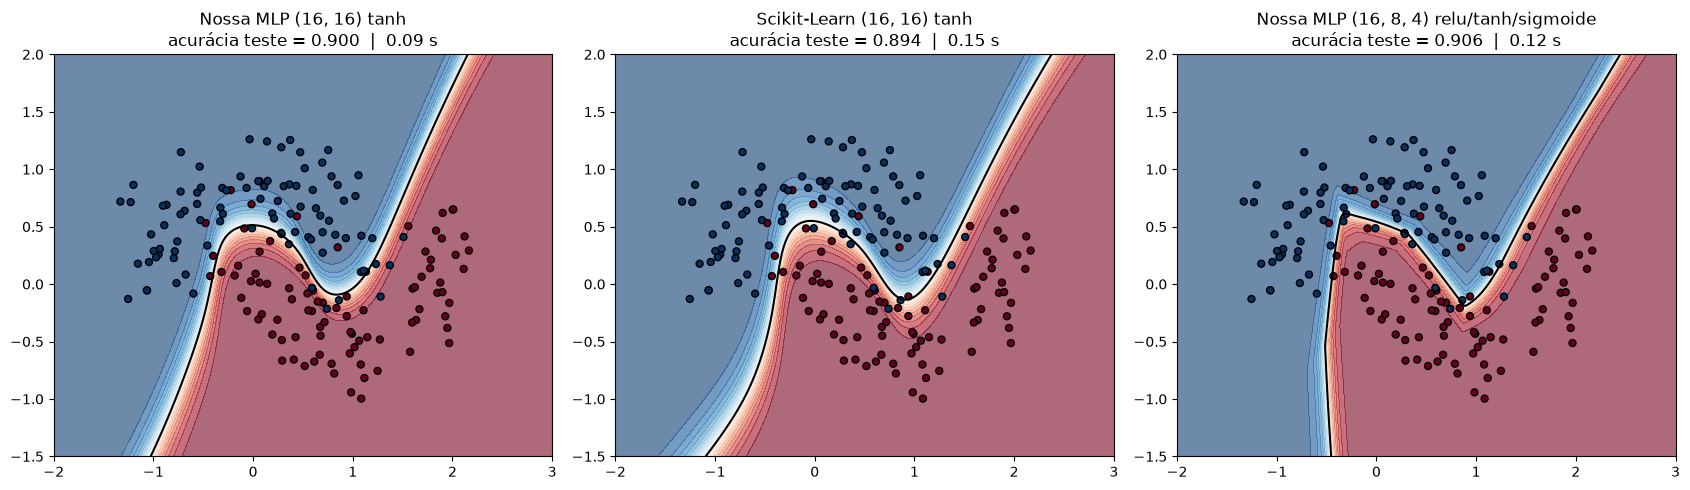

In [8]:
X_m, y_m = make_moons(n_samples=600, noise=0.25, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_m, y_m, test_size=0.3, random_state=0, stratify=y_m)

params_moons = dict(camadas_ocultas=(16, 16), ativacoes='tanh', taxa_aprendizado=0.01, max_epocas=500, semente=0)
params_misto = dict(camadas_ocultas=(16, 8, 4), ativacoes=['relu', 'tanh', 'sigmoide'], taxa_aprendizado=0.01, max_epocas=500, semente=0)

modelos_moons = {
    'Nossa MLP (16, 16) tanh': MLPClassificador(**params_moons),
    'Scikit-Learn (16, 16) tanh': modelo_sklearn(SkMLPClassifier, **params_moons),
    'Nossa MLP (16, 8, 4) relu/tanh/sigmoide': MLPClassificador(**params_misto),
}

xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grade = np.c_[xx.ravel(), yy.ravel()]

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
for ax, (nome, modelo) in zip(eixos, modelos_moons.items()):
    tempo = treinar(modelo, Xm_tr, ym_tr)
    prob = modelo.predict_proba(grade)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, prob, levels=20, cmap='RdBu_r', alpha=0.6)
    ax.contour(xx, yy, prob, levels=[0.5], colors='k', linewidths=1.5)
    ax.scatter(Xm_te[:, 0], Xm_te[:, 1], c=ym_te, cmap='RdBu_r', edgecolors='k', s=25)
    ax.set_title(f'{nome}\nacurácia teste = {modelo.score(Xm_te, ym_te):.3f}  |  {tempo:.2f} s')
plt.tight_layout()
plt.show()

## 5. Classificação de dígitos manuscritos: `load_digits`

Conjunto com 1797 imagens 8×8 de dígitos de 0 a 9 (64 atributos, 10 classes). Separo 20% para teste e padronizo os atributos (média 0, desvio 1) usando apenas as estatísticas do treino.

Ambos os modelos usam a mesma arquitetura — 2 camadas ocultas com 64 e 32 neurônios, ReLU, Adam — e os hiperparâmetros padrão.

In [9]:
X_d, y_d = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_d, y_d, test_size=0.2, random_state=42, stratify=y_d)
padronizador = StandardScaler().fit(Xd_tr)
Xd_tr, Xd_te = padronizador.transform(Xd_tr), padronizador.transform(Xd_te)
print(f'Treino: {Xd_tr.shape}   Teste: {Xd_te.shape}')

params_digits = dict(camadas_ocultas=(64, 32), ativacoes='relu', semente=0)
nosso_d = MLPClassificador(**params_digits)
sk_d = modelo_sklearn(SkMLPClassifier, **params_digits)

resultados = []
for nome, modelo in [('Nossa MLP', nosso_d), ('Scikit-Learn', sk_d)]:
    tempo = treinar(modelo, Xd_tr, yd_tr)
    resultados.append({
        'Modelo': nome,
        'Acurácia treino': modelo.score(Xd_tr, yd_tr),
        'Acurácia teste': modelo.score(Xd_te, yd_te),
        'Épocas': nosso_d.n_epocas_ if modelo is nosso_d else sk_d.n_iter_,
        'Perda final': (nosso_d.curva_perda_ if modelo is nosso_d else sk_d.loss_curve_)[-1],
        'Tempo (s)': tempo,
    })
pd.DataFrame(resultados).set_index('Modelo').round(4)

Treino: (1437, 64)   Teste: (360, 64)


,Acurácia treino,Acurácia teste,Épocas,Perda final,Tempo (s)
Modelo,,,,,
Nossa MLP,1.0,0.9833,113,0.0033,0.3102
Scikit-Learn,1.0,0.9667,109,0.0035,0.4707


In [10]:
nosso_d.resumo()

Camada         Neurônios   Ativação     Parâmetros
--------------------------------------------------
entrada               64
oculta 1              64   relu               4160
oculta 2              32   relu               2080
saída                 10   softmax             330
--------------------------------------------------
Total de parâmetros treináveis:               6570


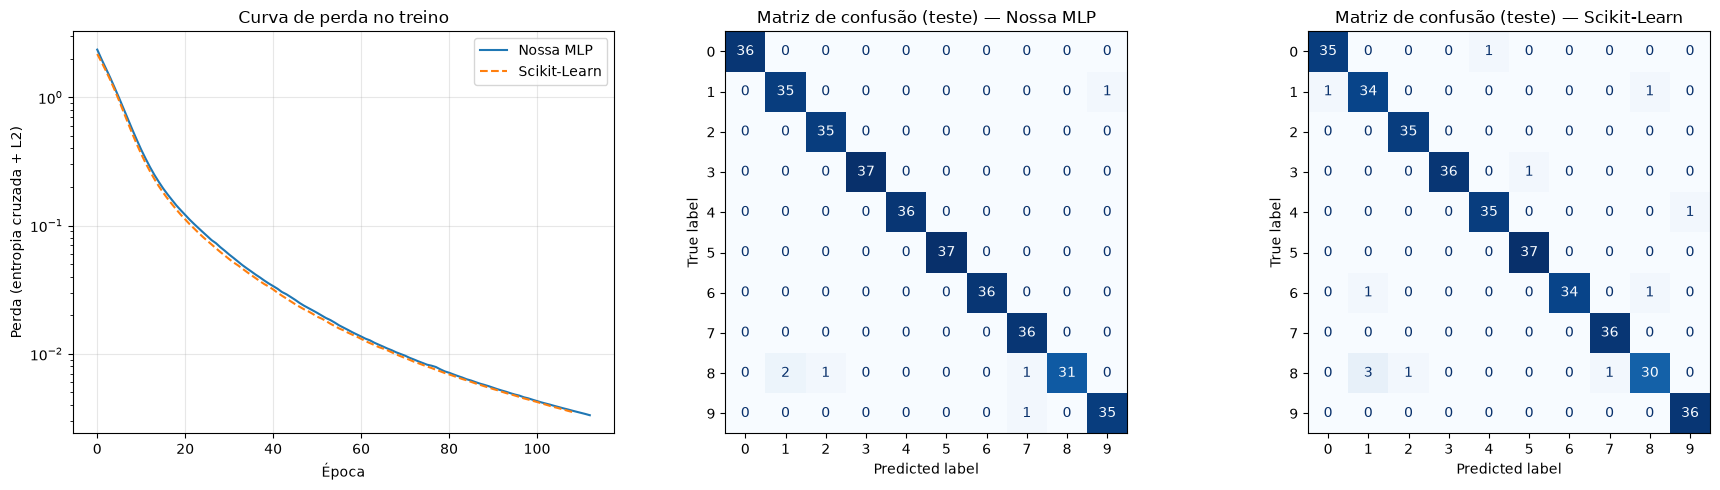

In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 5))

eixos[0].plot(nosso_d.curva_perda_, label='Nossa MLP')
eixos[0].plot(sk_d.loss_curve_, '--', label='Scikit-Learn')
eixos[0].set(xlabel='Época', ylabel='Perda (entropia cruzada + L2)', yscale='log', title='Curva de perda no treino')
eixos[0].legend()
eixos[0].grid(alpha=0.3)

for ax, (nome, modelo) in zip(eixos[1:], [('Nossa MLP', nosso_d), ('Scikit-Learn', sk_d)]):
    ConfusionMatrixDisplay.from_predictions(yd_te, modelo.predict(Xd_te), ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Matriz de confusão (teste) — {nome}')
plt.tight_layout()
plt.show()

## 6. Comparação de arquiteturas e funções de ativação

Agora vario o número de camadas, o número de neurônios, a função de ativação e o otimizador. Como o resultado de uma rede neural depende da inicialização aleatória dos pesos e da ordem dos mini-lotes, cada configuração é treinada com **5 sementes diferentes**, e reporto a média ± desvio padrão da acurácia de teste e o tempo médio de treino.

As duas últimas configurações usam ativações diferentes em cada camada e só existem na nossa implementação.

In [12]:
configuracoes = [
    dict(camadas_ocultas=(32,), ativacoes='relu'),
    dict(camadas_ocultas=(64, 32), ativacoes='relu'),
    dict(camadas_ocultas=(64, 32), ativacoes='tanh'),
    dict(camadas_ocultas=(64, 32), ativacoes='sigmoide'),
    dict(camadas_ocultas=(64, 32), ativacoes='identidade'),
    dict(camadas_ocultas=(128, 64, 32), ativacoes='relu'),
    dict(camadas_ocultas=(256, 128, 64, 32), ativacoes='relu'),
    dict(camadas_ocultas=(64, 32), ativacoes='relu', solver='sgd', taxa_aprendizado=0.05),
    dict(camadas_ocultas=(64, 32), ativacoes=['relu', 'tanh']),
    dict(camadas_ocultas=(128, 64, 32), ativacoes=['leaky_relu', 'tanh', 'sigmoide']),
]
sementes = range(5)


def avaliar(fabrica, X_tr, y_tr, X_te, y_te):
    """Treina um modelo por semente e devolve (média, desvio) do score de teste e o tempo médio."""
    scores, tempos = [], []
    for semente in sementes:
        modelo = fabrica(semente)
        if modelo is None:
            return None
        tempos.append(treinar(modelo, X_tr, y_tr))
        scores.append(modelo.score(X_te, y_te))
    return np.mean(scores), np.std(scores), np.mean(tempos)


def fmt(r):
    return '—' if r is None else f'{r[0]:.4f} ± {r[1]:.4f}'


def descrever(config):
    ativ = config['ativacoes']
    texto = f"{config['camadas_ocultas']} {ativ if isinstance(ativ, str) else '/'.join(ativ)}"
    if 'solver' in config:
        texto += f" {config['solver']} (lr={config['taxa_aprendizado']})"
    return texto


linhas = []
for config in configuracoes:
    r_nosso = avaliar(lambda s: MLPClassificador(**config, semente=s), Xd_tr, yd_tr, Xd_te, yd_te)
    r_sk = avaliar(lambda s: modelo_sklearn(SkMLPClassifier, **config, semente=s), Xd_tr, yd_tr, Xd_te, yd_te)
    linhas.append({
        'Configuração': descrever(config),
        'Acurácia teste — Nossa MLP': fmt(r_nosso),
        'Acurácia teste — Scikit-Learn': fmt(r_sk),
        'Tempo (s) — Nossa': f'{r_nosso[2]:.2f}',
        'Tempo (s) — Sklearn': '—' if r_sk is None else f'{r_sk[2]:.2f}',
    })
tabela_arquiteturas = pd.DataFrame(linhas).set_index('Configuração')
tabela_arquiteturas

,Acurácia teste — Nossa MLP,Acurácia teste — Scikit-Learn,Tempo (s) — Nossa,Tempo (s) — Sklearn
Configuração,,,,
"(32,) relu",0.9739 ± 0.0060,0.9706 ± 0.0052,0.30,0.46
"(64, 32) relu",0.9767 ± 0.0052,0.9706 ± 0.0022,0.35,0.48
"(64, 32) tanh",0.9767 ± 0.0042,0.9744 ± 0.0041,0.48,0.58
"(64, 32) sigmoide",0.9656 ± 0.0045,0.9600 ± 0.0033,0.62,0.84
"(64, 32) identidade",0.9594 ± 0.0028,0.9556 ± 0.0039,0.45,0.55
"(128, 64, 32) relu",0.9733 ± 0.0033,0.9789 ± 0.0022,0.51,0.73
"(256, 128, 64, 32) relu",0.9733 ± 0.0033,0.9761 ± 0.0057,1.17,1.62
"(64, 32) relu sgd (lr=0.05)",0.9700 ± 0.0062,0.9683 ± 0.0028,0.16,0.23
"(64, 32) relu/tanh",0.9794 ± 0.0052,—,0.50,—


## 7. Regressão

### 7.1 Função seno com ruído

Aproximação de $y = \sin(2x) + \varepsilon$, com $\varepsilon \sim \mathcal{N}(0;\ 0{,}1^2)$. Como é uma função de uma variável, dá para visualizar a curva aprendida por cada modelo.

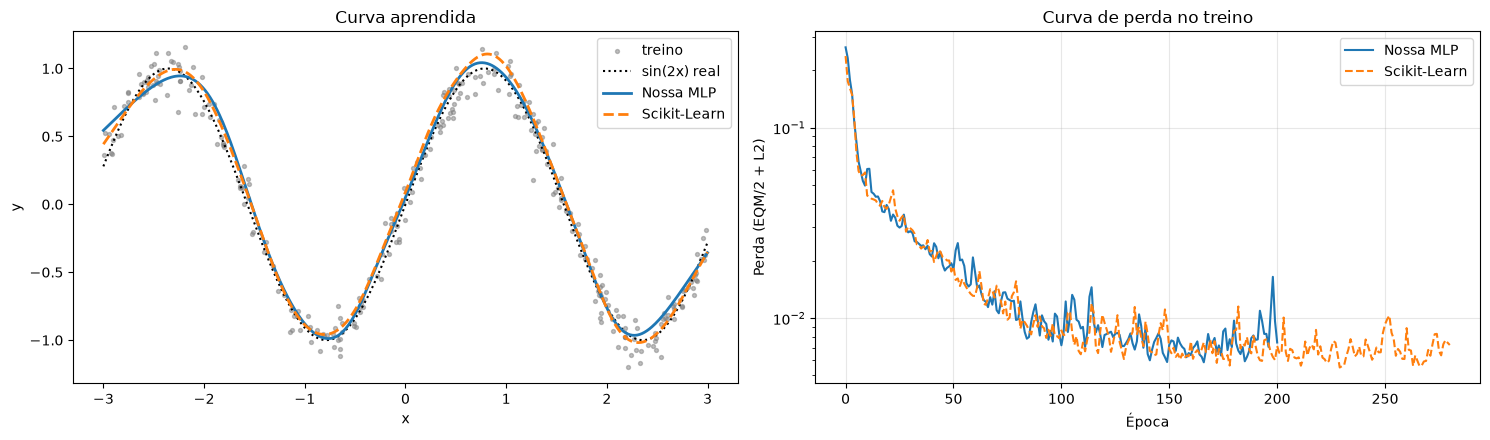

,R² teste,EQM teste,Épocas,Tempo (s)
Modelo,,,,
Nossa MLP,0.9682,0.0172,201,0.2581
Scikit-Learn,0.9704,0.0160,281,0.5608


In [13]:
rng = np.random.default_rng(0)
X_s = rng.uniform(-3, 3, (400, 1))
y_s = np.sin(2 * X_s[:, 0]) + rng.normal(0, 0.1, 400)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_s, y_s, test_size=0.25, random_state=0)

params_seno = dict(camadas_ocultas=(32, 32), ativacoes='tanh', taxa_aprendizado=0.01, tamanho_lote=32,
                   max_epocas=2000, n_epocas_sem_melhora=50, semente=0)
modelos_seno = {
    'Nossa MLP': MLPRegressor(**params_seno),
    'Scikit-Learn': modelo_sklearn(SkMLPRegressor, **params_seno),
}

x_plot = np.linspace(-3, 3, 500).reshape(-1, 1)
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5))
eixos[0].scatter(Xs_tr, ys_tr, s=8, c='gray', alpha=0.5, label='treino')
eixos[0].plot(x_plot, np.sin(2 * x_plot), 'k:', label='sin(2x) real')
linhas = []
for (nome, modelo), estilo in zip(modelos_seno.items(), ['-', '--']):
    tempo = treinar(modelo, Xs_tr, ys_tr)
    pred = modelo.predict(Xs_te)
    linhas.append({'Modelo': nome, 'R² teste': r2_score(ys_te, pred), 'EQM teste': mean_squared_error(ys_te, pred),
                   'Épocas': getattr(modelo, 'n_epocas_', getattr(modelo, 'n_iter_', None)), 'Tempo (s)': tempo})
    eixos[0].plot(x_plot, modelo.predict(x_plot), estilo, lw=2, label=nome)
    eixos[1].plot(getattr(modelo, 'curva_perda_', getattr(modelo, 'loss_curve_', None)), estilo, label=nome)
eixos[0].set(title='Curva aprendida', xlabel='x', ylabel='y')
eixos[0].legend()
eixos[1].set(title='Curva de perda no treino', xlabel='Época', ylabel='Perda (EQM/2 + L2)', yscale='log')
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
pd.DataFrame(linhas).set_index('Modelo').round(4)

O resultado acima é de uma única semente. Repetindo com 5 sementes:

In [14]:
sem_semente = {k: v for k, v in params_seno.items() if k != 'semente'}
r_nosso = avaliar(lambda s: MLPRegressor(**sem_semente, semente=s), Xs_tr, ys_tr, Xs_te, ys_te)
r_sk = avaliar(lambda s: modelo_sklearn(SkMLPRegressor, **sem_semente, semente=s), Xs_tr, ys_tr, Xs_te, ys_te)
print(f'R² teste — Nossa MLP:    {fmt(r_nosso)}')
print(f'R² teste — Scikit-Learn: {fmt(r_sk)}')

R² teste — Nossa MLP:    0.9649 ± 0.0049
R² teste — Scikit-Learn: 0.9703 ± 0.0016


### 7.2 Conjunto `load_diabetes`

Conjunto real com 442 pacientes, 10 atributos e, como alvo, uma medida da progressão da diabetes um ano depois. Padronizo atributos e alvo (o $R^2$ não é afetado por essa transformação do alvo) e comparo algumas arquiteturas, novamente com 5 sementes. Como o conjunto é pequeno e ruidoso, uso uma regularização L2 forte (`alpha=10`) e incluo uma regressão linear como referência.

In [15]:
X_db, y_db = load_diabetes(return_X_y=True)
Xdb_tr, Xdb_te, ydb_tr, ydb_te = train_test_split(X_db, y_db, test_size=0.25, random_state=0)
px = StandardScaler().fit(Xdb_tr)
Xdb_tr, Xdb_te = px.transform(Xdb_tr), px.transform(Xdb_te)
media_y, desvio_y = ydb_tr.mean(), ydb_tr.std()
ydb_tr, ydb_te = (ydb_tr - media_y) / desvio_y, (ydb_te - media_y) / desvio_y

configs_reg = [
    dict(camadas_ocultas=(16,), ativacoes='relu', alpha=10.0, max_epocas=1000),
    dict(camadas_ocultas=(32, 16), ativacoes='tanh', alpha=10.0, max_epocas=1000),
    dict(camadas_ocultas=(32, 16), ativacoes='relu', alpha=10.0, max_epocas=1000),
    dict(camadas_ocultas=(32, 16), ativacoes=['relu', 'tanh'], alpha=10.0, max_epocas=1000),
]
from sklearn.linear_model import LinearRegression

linear = LinearRegression().fit(Xdb_tr, ydb_tr).score(Xdb_te, ydb_te)
linhas = [{'Configuração': 'Regressão linear (referência)', 'R² teste — Nossa MLP': f'{linear:.4f}', 'R² teste — Scikit-Learn': f'{linear:.4f}'}]
for config in configs_reg:
    r_nosso = avaliar(lambda s: MLPRegressor(**config, semente=s), Xdb_tr, ydb_tr, Xdb_te, ydb_te)
    r_sk = avaliar(lambda s: modelo_sklearn(SkMLPRegressor, **config, semente=s), Xdb_tr, ydb_tr, Xdb_te, ydb_te)
    linhas.append({'Configuração': descrever(config), 'R² teste — Nossa MLP': fmt(r_nosso), 'R² teste — Scikit-Learn': fmt(r_sk)})
pd.DataFrame(linhas).set_index('Configuração')

,R² teste — Nossa MLP,R² teste — Scikit-Learn
Configuração,,
Regressão linear (referência),0.3594,0.3594
"(16,) relu",0.3758 ± 0.0060,0.3807 ± 0.0052
"(32, 16) tanh",0.3752 ± 0.0009,0.3739 ± 0.0014
"(32, 16) relu",0.3763 ± 0.0005,0.3772 ± 0.0016
"(32, 16) relu/tanh",0.3776 ± 0.0031,—


## 8. Conclusões

**Corretude da implementação**

- A verificação numérica mostrou erro relativo entre o gradiente analítico e o numérico da ordem de $10^{-8}$ a $10^{-9}$ em todas as redes testadas (diferentes profundidades, ativações misturadas, saída softmax, sigmoide e de regressão), confirmando que a retropropagação está correta.
- Copiando os pesos treinados pelo Scikit-Learn para a nossa MLP, as probabilidades previstas coincidem até a precisão de máquina ($\sim 10^{-16}$) para todas as ativações, ou seja, a propagação direta é idêntica.

**Comparação de desempenho com o Scikit-Learn**

- Com os mesmos hiperparâmetros, as duas implementações têm desempenho equivalente: no `load_digits` a acurácia de teste ficou em torno de 96–98% para ambas, e as curvas de perda praticamente se sobrepõem. As diferenças entre as duas ficam dentro da variação causada pela semente aleatória (desvio padrão de ~0,2–0,6 p.p.), sem vantagem sistemática para nenhum lado.
- Nas regressões o comportamento também foi equivalente: $R^2 \approx 0{,}97$ na função seno e $R^2 \approx 0{,}38$ no `load_diabetes` (ligeiramente acima da regressão linear, o que indica que esse conjunto tem pouca estrutura não linear a explorar).
- Os resultados não são idênticos época a época porque a sequência de números aleatórios (inicialização e embaralhamento dos lotes) é gerada de forma diferente em cada implementação, mas a distribuição dos resultados é a mesma.
- O tempo de treino foi da mesma ordem de grandeza; a nossa versão foi um pouco mais rápida nesses conjuntos pequenos, provavelmente porque o Scikit-Learn faz validações e tratamentos adicionais (dados esparsos, `early_stopping`, `warm_start`, etc.) que não foram implementados aqui.

**Efeito da arquitetura e das ativações** (`load_digits`)

- ReLU e tanh tiveram os melhores resultados; a sigmoide foi um pouco pior, e a ativação identidade foi a pior, como esperado: sem não linearidade, uma MLP com várias camadas equivale a um modelo linear (regressão logística).
- Aumentar a profundidade de 2 para 3 ou 4 camadas não trouxe ganho relevante — o problema é simples o bastante para uma ou duas camadas ocultas — e aumentou o tempo de treino.
- O SGD com momento chegou a uma acurácia parecida à do Adam, mas exigiu uma taxa de aprendizado maior.
- A possibilidade de usar ativações diferentes em cada camada, que não existe no Scikit-Learn, funcionou corretamente (gradiente verificado e boas acurácias), com resultados no mesmo patamar das melhores configurações homogêneas.

**Limitações da implementação**: não há `early_stopping` com conjunto de validação, agendamento da taxa de aprendizado, momento de Nesterov, L-BFGS ou suporte a matrizes esparsas, recursos que o Scikit-Learn oferece.